# Regresión supervisada con Regresión Lineal Múltiple

## Objetivo

El objetivo de este notebook es desarrollar y evaluar un modelo de regresión supervisada utilizando **Regresión Lineal Múltiple** para estimar la popularidad de las canciones de Spotify a partir de sus características.

A diferencia de los modelos de clasificación desarrollados anteriormente, en este caso la variable objetivo es `popularity`, que representa un valor numérico. Por lo tanto, el modelo busca estimar una puntuación de popularidad en lugar de asignar una categoría.

El análisis contempla la validación cruzada, la evaluación mediante métricas de error y el coeficiente de determinación \(R^2\). Además, se examinará la relación entre los valores reales y predichos, junto con los coeficientes del modelo, para interpretar la influencia lineal estimada de las características sobre la variable objetivo.

In [2]:
import pandas as pd
import numpy as np
import os
import sys

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

"""
En caso de que Python no encuentre en la ruta los otros directorios,
ejecutar esta configuración
"""

sys.path.append(os.path.abspath(".."))

---

## Carga de los conjuntos de datos

Se cargan los datasets de entrenamiento y prueba previamente preprocesados para la tarea de regresión.

- **Conjunto de entrenamiento:** se utiliza para realizar la validación cruzada y ajustar el modelo definitivo.
- **Conjunto de prueba:** se reserva para evaluar la capacidad de generalización del modelo sobre observaciones que no participaron en su entrenamiento.

Se crean copias de ambos datasets y se inspeccionan sus primeras filas para comprobar la estructura y el contenido de los datos antes de continuar con el análisis.

In [3]:
data_train = pd.read_csv(
    "../../../dataset/Spotify_train_preprocesado_regresion.csv"
)

data_test = pd.read_csv(
    "../../../dataset/Spotify_test_preprocesado_regresion.csv"
)

df_train = data_train.copy()
df_test = data_test.copy()

print("Dataset de entrenamiento:")
display(df_train.head())

print("\nDataset de prueba:")
display(df_test.head())


Dataset de entrenamiento:


,bin__track_genre_0,bin__track_genre_1,bin__track_genre_2,bin__track_genre_3,bin__track_genre_4,bin__track_genre_5,bin__track_genre_6,ord__duration_category,num__danceability,num__energy,...,num__loudness,num__mode,num__speechiness,num__acousticness,num__instrumentalness,num__liveness,num__valence,num__tempo,num__duration_min,popularity
0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.360656,0.407609,0.005418,...,-0.557598,0.751125,-0.804229,0.532848,-0.562123,-0.436477,1.542740,-0.147610,-0.695300,21.0
1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.360656,0.100464,-0.034422,...,-0.017461,0.751125,-0.785413,0.623235,-0.606882,-0.678120,1.183864,0.437714,-0.191994,0.0
2,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.927115,-1.881489,0.216573,...,0.430609,0.751125,-0.519639,-0.618079,-0.580263,-0.985860,-1.305115,0.437984,0.625209,45.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.360656,1.746296,0.336094,...,0.571210,-1.331337,-0.500823,-0.710274,-0.606882,-0.635477,-0.506326,0.064335,-0.879964,4.0
4,0.0,0.0,0.0,0.0,1.0,0.0,1.0,-0.360656,0.726344,-1.795371,...,-2.390784,-1.331337,1.124396,1.430692,1.793755,-0.671013,1.195440,2.664353,-0.772929,55.0



Dataset de prueba:


,bin__track_genre_0,bin__track_genre_1,bin__track_genre_2,bin__track_genre_3,bin__track_genre_4,bin__track_genre_5,bin__track_genre_6,ord__duration_category,num__danceability,num__energy,...,num__loudness,num__mode,num__speechiness,num__acousticness,num__instrumentalness,num__liveness,num__valence,num__tempo,num__duration_min,popularity
0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.927115,-1.452645,-1.914892,...,-2.318107,0.751125,-0.700742,1.813330,1.793755,-0.700153,-1.619613,-0.133029,1.330330,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.360656,1.798453,0.626930,...,1.478109,0.751125,0.865678,-0.675324,-0.606764,1.390062,1.450127,-0.406397,-0.528812,1.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.360656,0.639416,0.224541,...,0.842404,0.751125,-0.199770,-0.940037,-0.606785,-0.724317,1.303489,2.353574,-0.550148,7.0
3,1.0,0.0,0.0,0.0,1.0,1.0,0.0,-1.648427,-0.067596,0.754419,...,0.438615,0.751125,2.126046,1.707878,-0.606882,2.409939,0.292462,-1.350621,-1.566635,23.0
4,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.927115,0.830657,1.093063,...,1.257701,0.751125,-0.380872,-0.942719,1.793755,-1.048403,1.006355,0.096426,1.158399,0.0


---

## Separación de variables predictoras y variable objetivo

Se separan las características predictoras de la variable objetivo `popularity`.

- **X_train y X_test:** contienen las características de las canciones utilizadas para estimar su popularidad.
- **y_train y y_test:** contienen los valores numéricos reales de popularidad.

La variable objetivo se excluye de las características predictoras para evitar que el modelo utilice directamente el valor que debe estimar.

Esta separación permite entrenar el modelo con las características disponibles y posteriormente comparar sus predicciones con los valores reales.

In [4]:
# Separación de variables predictoras y objetivo
X_train = df_train.drop(
    columns=["popularity"]
)

y_train = df_train[
    "popularity"
]

X_test = df_test.drop(
    columns=["popularity"]
)

y_test = df_test[
    "popularity"
]

---

## Validación cruzada de Regresión Lineal Múltiple

Se utiliza el algoritmo `KFold` con cinco particiones para evaluar el modelo mediante validación cruzada.

El conjunto de entrenamiento se divide en cinco particiones. En cada iteración, cuatro se utilizan para entrenar el modelo y la restante para validarlo. El procedimiento se repite hasta que todas las particiones han sido utilizadas como conjunto de validación.

Se utiliza `shuffle=True` para mezclar las observaciones antes de dividirlas y `random_state=42` para facilitar la reproducibilidad.

El modelo implementado es `LinearRegression`, que estima una relación lineal entre las características predictoras y la variable objetivo. En términos generales, busca encontrar los coeficientes que minimizan la suma de los errores cuadrados de las predicciones sobre los datos de entrenamiento.

Para evaluar su rendimiento se utilizan las siguientes métricas:

- **MAE (Mean Absolute Error):** mide el promedio de las diferencias absolutas entre los valores reales y predichos.
- **MSE (Mean Squared Error):** calcula el promedio de los errores al cuadrado, penalizando con mayor intensidad los errores grandes.
- **RMSE (Root Mean Squared Error):** corresponde a la raíz cuadrada del MSE y expresa el error en la misma unidad que la variable objetivo.
- **R² (coeficiente de determinación):** mide cuánto mejora el modelo respecto de una predicción basada en la media de los valores reales, según la variabilidad observada en los datos evaluados.

Para cada métrica se calcula el promedio y la desviación estándar entre las cinco particiones. En MAE, MSE y RMSE, los valores menores indican menos error; para \(R^2\), los valores más altos suelen representar un mejor ajuste, aunque un resultado negativo indica que el modelo rinde peor que predecir la media del conjunto evaluado.

## Análisis de las métricas de validación cruzada

Una vez finalizada la validación cruzada, se calculan los promedios de las métricas obtenidas en las cinco particiones.

**CONSIDERACIÓN**: Scikit-learn expresa por defecto las métricas de error configuradas como `neg_mean_absolute_error`, `neg_mean_squared_error` y `neg_root_mean_squared_error` mediante valores negativos, porque su mecanismo de evaluación está diseñado para maximizar las puntuaciones.

Por este motivo, **se cambia el signo de los promedios de MAE, MSE y RMSE para recuperar sus valores positivos e interpretarlos como errores.**

La desviación estándar se calcula sobre las puntuaciones originales. Aunque el signo negativo no modifica su magnitud, debe considerarse que estos valores representan la variabilidad entre las particiones y no un intervalo de confianza.

Este resumen permite evaluar tanto el nivel de error del modelo como la estabilidad de su rendimiento durante la validación cruzada.

In [5]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

modelo_regresion = LinearRegression()

scores_regresion = cross_validate(
    modelo_regresion,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Convertir MAE, MSE y RMSE a valores positivos
resultados_regresion = {
    "mae": -scores_regresion["test_mae"].mean(),
    "mse": -scores_regresion["test_mse"].mean(),
    "rmse": -scores_regresion["test_rmse"].mean(),
    "r2": scores_regresion["test_r2"].mean()
}

desviaciones_regresion = {
    "mae": scores_regresion["test_mae"].std(),
    "mse": scores_regresion["test_mse"].std(),
    "rmse": scores_regresion["test_rmse"].std(),
    "r2": scores_regresion["test_r2"].std()
}

print("Resultados de Regresión Lineal Múltiple:")

for metrica, valor in resultados_regresion.items():
    print(f"{metrica.upper()}: {valor:.4f}")

print("\nDesviación estándar entre particiones:")

for metrica, valor in desviaciones_regresion.items():
    print(f"{metrica.upper()}: {valor:.4f}")

Resultados de Regresión Lineal Múltiple:
MAE: 17.9512
MSE: 470.4369
RMSE: 21.6893
R2: 0.0516

Desviación estándar entre particiones:
MAE: 0.0939
MSE: 4.4348
RMSE: 0.1020
R2: 0.0030


---

## Visualización de los errores y del coeficiente de determinación

Se construye una visualización con dos gráficos para facilitar la interpretación de los resultados de la validación cruzada.

**Gráfico de errores:** representa los valores promedio de MAE, MSE y RMSE. Permite comparar las magnitudes de los errores del modelo. Sin embargo, el MSE se expresa en unidades al cuadrado, por lo que su escala no es directamente comparable con la de MAE y RMSE.

**Gráfico de \(R^2\):** muestra el promedio del coeficiente de determinación para analizar el ajuste del modelo respecto de una referencia basada en la media de los valores reales.

Los resultados deben interpretarse conjuntamente, ya que un modelo puede presentar errores relativamente pequeños y, aun así, explicar una proporción limitada de la variabilidad de la popularidad.

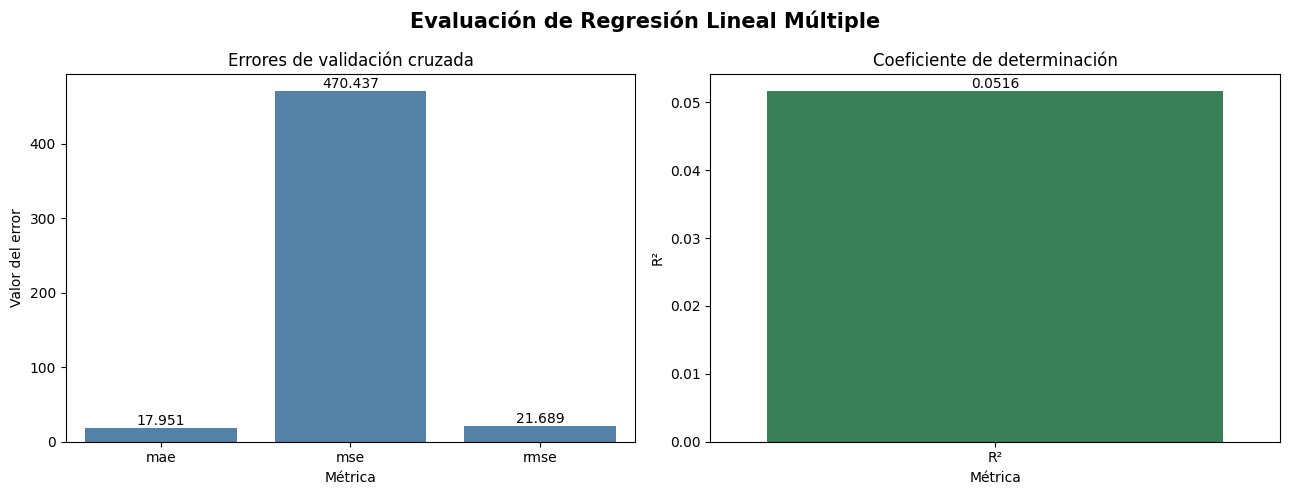

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metricas_error = ["mae", "mse", "rmse"]
valores_error = [
    resultados_regresion[m]
    for m in metricas_error
]

sns.barplot(
    x=metricas_error,
    y=valores_error,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Errores de validación cruzada")
axes[0].set_xlabel("Métrica")
axes[0].set_ylabel("Valor del error")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f")

sns.barplot(
    x=["R²"],
    y=[resultados_regresion["r2"]],
    ax=axes[1],
    color="seagreen"
)

axes[1].set_title("Coeficiente de determinación")
axes[1].set_xlabel("Métrica")
axes[1].set_ylabel("R²")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.4f")

plt.suptitle(
    "Evaluación de Regresión Lineal Múltiple",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

---

## Entrenamiento definitivo de Regresión Lineal Múltiple

Después de completar la validación cruzada, se entrena el modelo con la totalidad del conjunto de entrenamiento mediante el método `fit()`.

Posteriormente, se inspeccionan dos componentes del modelo:

- **Intercepto:** representa el valor estimado de la variable objetivo cuando todas las características predictoras toman el valor cero.
- **Coeficientes:** representan los cambios estimados en la popularidad predicha ante un aumento de una unidad en una característica, manteniendo constantes las demás.

La interpretación del intercepto y de los coeficientes depende de la codificación y la escala de las variables. Por ello, no deben interpretarse automáticamente como relaciones causales.

In [7]:
modelo_regresion.fit(X_train, y_train)

print("Modelo de Regresión Lineal Múltiple entrenado correctamente.")

print("\nIntercepto:")
print(modelo_regresion.intercept_)

print("\nCantidad de coeficientes:", len(modelo_regresion.coef_))

Modelo de Regresión Lineal Múltiple entrenado correctamente.

Intercepto:
29.5665689550113

Cantidad de coeficientes: 20


---

## Evaluación final del modelo con datos de prueba

Se realizan predicciones sobre `X_test` mediante el método `predict()` y se comparan con los valores reales de `y_test`.

Se calculan las siguientes métricas:

- **MAE:** error absoluto promedio de las predicciones.
- **MSE:** error cuadrático medio.
- **RMSE:** raíz del error cuadrático medio.
- **R²:** coeficiente de determinación sobre el conjunto de prueba.

Esta evaluación permite estimar el desempeño del modelo sobre datos que no participaron en el entrenamiento.

Los resultados del conjunto de prueba deben interpretarse como la evaluación final de la configuración utilizada. Si el rendimiento es considerablemente peor que durante la validación cruzada, podría existir una diferencia entre las observaciones de entrenamiento y prueba, o el modelo podría no capturar adecuadamente las relaciones presentes en los datos.

In [8]:
y_pred_regresion = modelo_regresion.predict(X_test)

metricas_test_regresion = {
    "MAE": mean_absolute_error(y_test, y_pred_regresion),
    "MSE": mean_squared_error(y_test, y_pred_regresion),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_regresion)),
    "R2": r2_score(y_test, y_pred_regresion)
}

print("Resultados de Regresión Lineal Múltiple en el conjunto de prueba:")

for metrica, valor in metricas_test_regresion.items():
    print(f"{metrica}: {valor:.4f}")

Resultados de Regresión Lineal Múltiple en el conjunto de prueba:
MAE: 17.9553
MSE: 470.3440
RMSE: 21.6874
R2: 0.0507


---

## Análisis de la popularidad real frente a la predicha

Se construye un gráfico de dispersión que compara los valores reales de popularidad con las predicciones del modelo.

Cada punto representa una canción: su posición horizontal corresponde a la popularidad real y su posición vertical, a la popularidad estimada.

Se agrega una línea diagonal de referencia que representa la situación ideal, en la que cada predicción coincide exactamente con el valor real.

- Los puntos cercanos a la diagonal indican predicciones más precisas.
- Los puntos alejados de la diagonal representan errores de mayor magnitud.
- Los patrones sistemáticos por encima o por debajo de la diagonal pueden indicar que el modelo tiende a sobreestimar o subestimar ciertos valores.

Esta visualización complementa las métricas de error y permite identificar patrones que no siempre son evidentes a partir de un único indicador numérico.

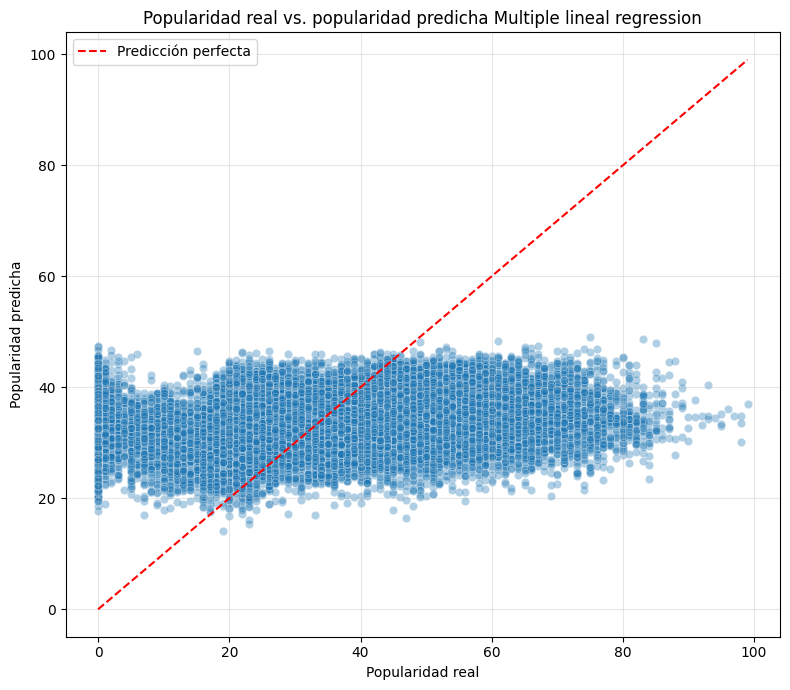

In [ ]:
# Calcular R²
r2 = r2_score(y_test, y_pred_regresion)

plt.figure(figsize=(8, 7))

sns.scatterplot(
    x=y_test,
    y=y_pred_regresion,
    alpha=0.35
)

limite_min = min(y_test.min(), y_pred_regresion.min())
limite_max = max(y_test.max(), y_pred_regresion.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--",
    color="red",
    label="Predicción perfecta"
)

# Etiqueta con el valor de R²
plt.text(
    0.05,
    0.95,
    f"$R^2 = {r2:.4f}$",
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.8
    )
)

plt.title(
    "Popularidad real vs. popularidad predicha - Regresión lineal múltiple"
)
plt.xlabel("Popularidad real")
plt.ylabel("Popularidad predicha")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---

## Interpretación de los coeficientes del modelo

Se construye una tabla con los coeficientes estimados para cada característica predictora. Luego, se calcula su valor absoluto para ordenar las variables según la magnitud de sus coeficientes.

Se seleccionan las 15 características con mayor magnitud absoluta y se representan mediante un gráfico de barras.

La interpretación considera dos aspectos:

- **Signo del coeficiente:** un coeficiente positivo indica que un aumento de la característica se asocia con un aumento de la popularidad predicha, manteniendo constantes las demás variables. Un coeficiente negativo indica una asociación lineal estimada en sentido contrario.
- **Magnitud del coeficiente:** indica el tamaño del cambio estimado por unidad de la característica, condicionado a la escala y codificación de esa variable.

La magnitud absoluta permite ordenar los coeficientes dentro del modelo, pero **no constituye por sí sola una medida universal de importancia** cuando las variables tienen escalas o codificaciones diferentes.

Además, los coeficientes describen asociaciones aprendidas por el modelo y no demuestran relaciones causales entre las características musicales y la popularidad.

,Caracteristica,Coeficiente
2,bin__track_genre_2,5.970602
3,bin__track_genre_3,2.882779
15,num__instrumentalness,-2.226428
1,bin__track_genre_1,-2.122944
17,num__valence,-2.059162
11,num__loudness,1.852996
9,num__energy,-1.571336
7,ord__duration_category,-1.395616
13,num__speechiness,-1.382681
5,bin__track_genre_5,1.361286


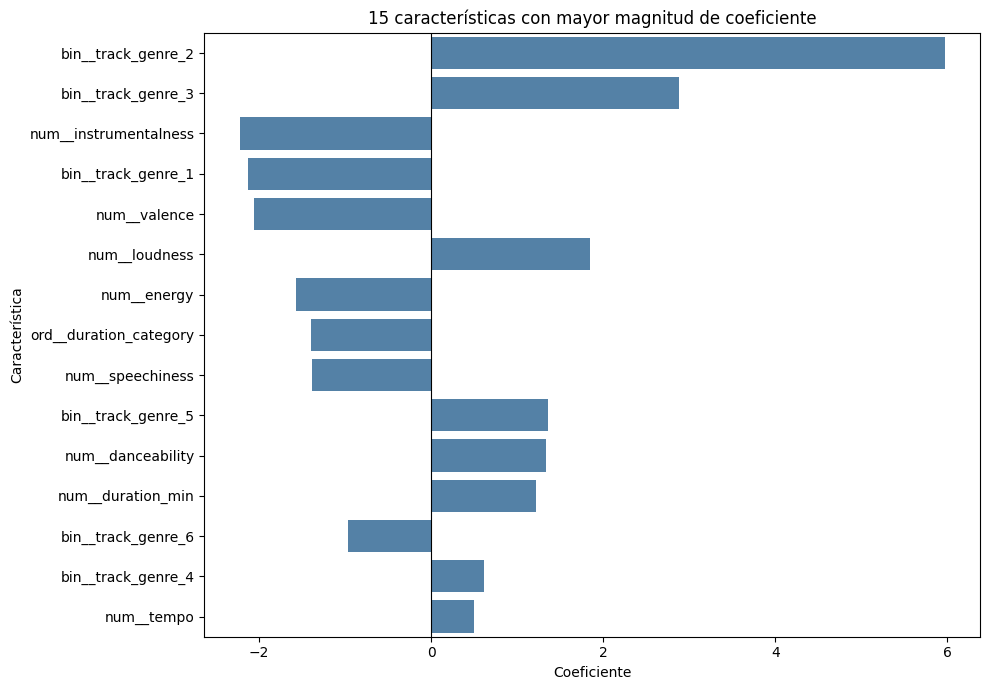

In [10]:
coeficientes = pd.DataFrame({
    "Caracteristica": X_train.columns,
    "Coeficiente": modelo_regresion.coef_
})

coeficientes["Valor_absoluto"] = coeficientes["Coeficiente"].abs()

coeficientes = coeficientes.sort_values(
    by="Valor_absoluto",
    ascending=False
)

display(coeficientes.drop(columns="Valor_absoluto"))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=coeficientes.head(15),
    x="Coeficiente",
    y="Caracteristica",
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("15 características con mayor magnitud de coeficiente")
plt.xlabel("Coeficiente")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

---

## Conclusiones de Regresión Lineal Múltiple

En este notebook se implementó un modelo de Regresión Lineal Múltiple para estimar la popularidad numérica de las canciones de Spotify a partir de sus características.

El modelo se evaluó mediante validación cruzada de cinco particiones y posteriormente se entrenó con la totalidad del conjunto de entrenamiento. Su rendimiento final se examinó sobre el conjunto de prueba utilizando MAE, MSE, RMSE y \(R^2\).

También se analizaron las diferencias entre la popularidad real y predicha mediante un gráfico de dispersión, y se estudiaron los coeficientes para identificar las características con mayores magnitudes dentro de la relación lineal estimada.

La conclusión definitiva debe considerar los valores de las métricas obtenidas, la distribución de los errores y la capacidad del modelo para representar la variabilidad de la popularidad.

Finalmente, estos resultados podrán utilizarse como referencia para comparar la regresión lineal con otros modelos de regresión y determinar si un modelo lineal resulta suficiente para capturar los patrones presentes en los datos de Spotify.